# Rust benchmarks

How much the Rust extension speeds up monod, measured against the Python path on
synthetic data and on PBMC 10k, and whether the two paths agree.

| Section | What is measured |
|---|---|
| 1 | `eval_kld_2d` and `eval_kld_grad_2d`: one KLD (and gradient) evaluation, Rust against Python |
| 2 | `optimize_genes_2d_sd`: the Rust L-BFGS-B kernel against scipy, one gene and many genes |
| 3 | The `gradient_params` flags that select the optimizer, timed on 50 PBMC genes |
| 4 | Scaling on PBMC 10k: gene count, core count and cell count |
| 5 | Concordance: do scipy and the Rust kernel reach the same optima? |

Sections 1–2 use synthetic Bursty data, so they run without a dataset; sections 3–5
need `example_h5ad/processed_pbmc_10k_raw.h5ad`.  The whole notebook takes about
15 minutes on a 24-core machine.

Related notebooks: `rust_extension.ipynb` checks that the extension is active and
introduces the flags; `rust_pipeline.ipynb` shows the all-Rust loading path
(`searchdata_from_h5ad`); `gpu.ipynb` adds the GPU backend to the comparison.


## Setup


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import os, sys, time, gc, warnings
import numpy as np
import scipy.optimize
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from concurrent.futures import ThreadPoolExecutor

import monod.cme_toolbox as cme_toolbox
from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.extract_data import extract_data, grid_limits, select_expressed_genes
from monod.inference import InferenceParameters, searchdata_from_adata
import monod_core as _mc

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)
n_cpu = os.cpu_count() or 4
print(f"monod_core : {_mc.__file__}")
print(f"_HAS_RUST  : {_HAS_RUST}")
print(f"CPUs       : {n_cpu}")

# ── shared benchmark config ──────────────────────────────────────────────────
BIO_MODEL     = "Bursty"
FIXED_QUAD_T  = 10.0      # CMEModel's default quadrature horizon
QUAD_ORDER    = 10
FD_EPS        = 1e-6
LB = [-3.0, -3.0, -3.0]   # parameter bounds (log10)
UB = [ 3.0,  3.0,  3.0]
BOUNDS = list(zip(LB, UB))
EPS   = 1e-15

# ── colour scheme ────────────────────────────────────────────────────────────
C_PY   = "steelblue"
C_RUST = "firebrick"


monod_core : /home/coakes/miniconda3/envs/monod/lib/python3.11/site-packages/monod_core/__init__.py
_HAS_RUST  : True
CPUs       : 24


In [3]:
# ── Synthetic gene factory ────────────────────────────────────────────────────
# Returns (u_idx, s_idx, f, limits) for a single gene.

def make_gene(p_log, limits, n_cells=3000, rng=None):
    """Sample n_cells observations from a Bursty model and return unique histogram."""
    if rng is None:
        rng = np.random.default_rng(0)
    pss = np.array(_mc.eval_model_pss_2d(BIO_MODEL, list(p_log), limits,
                                          FIXED_QUAD_T, QUAD_ORDER))
    flat = rng.choice(len(pss), size=n_cells, p=pss)
    ui   = (flat // limits[1]).astype(np.int64)
    si   = (flat  % limits[1]).astype(np.int64)
    pairs = np.column_stack([ui, si])
    up, cnt = np.unique(pairs, axis=0, return_counts=True)
    return (
        up[:, 0].astype(np.uint64).tolist(),
        up[:, 1].astype(np.uint64).tolist(),
        (cnt / n_cells).tolist(),
        [int(v) for v in limits],
    )

def make_sd(p_logs, limits, n_cells=3000, rng=None):
    """Sample n_cells cells for each gene in p_logs and build the Rust SearchData the
    inference pipeline hands to the optimizer.  Returns (sd, layers, coords, freqs)."""
    if rng is None:
        rng = np.random.default_rng(0)
    cols_u, cols_s = [], []
    for p_log in p_logs:
        pss = np.array(_mc.eval_model_pss_2d(BIO_MODEL, list(p_log), limits,
                                              FIXED_QUAD_T, QUAD_ORDER))
        flat = rng.choice(len(pss), size=n_cells, p=pss)
        cols_u.append(flat // limits[1]); cols_s.append(flat % limits[1])
    layers = [np.ascontiguousarray(np.column_stack(cols), dtype=np.int64) for cols in (cols_u, cols_s)]
    return sd_from_layers(layers, limits) + (layers,)

def sd_from_layers(layers, limits):
    """Rust SearchData from (n_cells, n_genes) count layers sharing one grid."""
    layers = [np.ascontiguousarray(x, dtype=np.int64) for x in layers]
    n_cells, n_genes = layers[0].shape
    coords, freqs = _mc.make_state_dist(layers)
    lim = np.ascontiguousarray(np.tile(np.asarray(limits, dtype=np.int64)[:, None], (1, n_genes)))
    sd = _mc.searchdata_from_arrays(layers, ["unspliced", "spliced"], lim, coords, freqs,
                                    [f"gene_{i}" for i in range(n_genes)], n_cells, "unique")
    return sd, coords, freqs

# Reference gene used in single-gene benchmarks
P_REF   = [-0.8, -0.5, -1.2]
LIMITS  = [24, 20]
rng0 = np.random.default_rng(7)
U_REF, S_REF, F_REF, LIM_REF = make_gene(P_REF, LIMITS, n_cells=5000, rng=rng0)

print(f"Reference gene: {len(F_REF)} unique microstates from 5 000 cells, grid {LIMITS[0]}×{LIMITS[1]}")

Reference gene: 47 unique microstates from 5 000 cells, grid 24×20


---
## 1  KLD Fast-Paths

Two Rust functions replace the Python path inside `CMEModel.eval_model_kld` and
`CMEModel.eval_model_kld_and_grad` whenever the model is 2-D, the histogram type
is `"unique"`, and the quadrature method is `"fixed_quad"`.

They activate **automatically** — no flag required.

```
Python path:  eval_model_pss_2d → Python indexing → np.sum(f * log(f/pss))
Rust path:    eval_kld_2d       → single C-extension call, no Python round-trip
```

### 1a  `eval_kld_2d`

Computes KLD(data ‖ model) for a unique histogram in one call.

In [4]:
# ── Correctness check ─────────────────────────────────────────────────────────
# Same quadrature as the Rust calls below, so the two paths are compared like for like.
model = CMEModel(BIO_MODEL, "None", fixed_quad_T=FIXED_QUAD_T, quad_order=QUAD_ORDER)

# Python path
pss_py   = model.eval_model_pss(np.array(P_REF), LIMITS)
np.clip(pss_py, EPS, None, out=pss_py)
x_arr    = np.column_stack([U_REF, S_REF]).astype(int)
f_arr    = np.array(F_REF)
kld_py   = float(np.sum(f_arr * np.log(f_arr / pss_py[x_arr[:, 0], x_arr[:, 1]])))

# Rust path
kld_rust = _mc.eval_kld_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                             FIXED_QUAD_T, QUAD_ORDER)

print(f"Python KLD : {kld_py:.8f}")
print(f"Rust   KLD : {kld_rust:.8f}")
print(f"Difference : {abs(kld_py - kld_rust):.2e}")

Python KLD : 0.00634565
Rust   KLD : 0.00634565
Difference : 3.47e-18


In [5]:
# ── Benchmark: eval_kld_2d ────────────────────────────────────────────────────
N_REPS = 500

t0 = time.perf_counter()
for _ in range(N_REPS):
    pss = model.eval_model_pss(np.array(P_REF), LIMITS)
    np.clip(pss, EPS, None, out=pss)
    _ = float(np.sum(f_arr * np.log(f_arr / pss[x_arr[:, 0], x_arr[:, 1]])))
t_py_kld = (time.perf_counter() - t0) / N_REPS * 1e3

t0 = time.perf_counter()
for _ in range(N_REPS):
    _ = _mc.eval_kld_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                         FIXED_QUAD_T, QUAD_ORDER)
t_ru_kld = (time.perf_counter() - t0) / N_REPS * 1e3

print(f"Python  eval_kld   : {t_py_kld:.3f} ms")
print(f"Rust    eval_kld_2d: {t_ru_kld:.3f} ms")
print(f"Speedup            : {t_py_kld / t_ru_kld:.1f}×")

Python  eval_kld   : 0.125 ms
Rust    eval_kld_2d: 0.027 ms
Speedup            : 4.7×


### 1b  `eval_kld_grad_2d`

Computes KLD **and** its finite-difference Jacobian in a single call.  All
`n_params + 1` PSS evaluations (base + one per parameter) run in parallel via
rayon with the GIL released.

In [6]:
# ── Correctness check ─────────────────────────────────────────────────────────
def py_kld_grad(p, limits, u_idx, s_idx, f):
    """Pure-Python finite-difference gradient (sequential)."""
    pss0 = model.eval_model_pss(np.asarray(p), limits)
    np.clip(pss0, EPS, None, out=pss0)
    x_a = np.column_stack([u_idx, s_idx]).astype(int)
    f_a = np.array(f)
    kld0 = float(np.sum(f_a * np.log(f_a / pss0[x_a[:, 0], x_a[:, 1]])))
    grad = []
    for i in range(len(p)):
        p_eps = list(p); p_eps[i] += FD_EPS
        pss_e = model.eval_model_pss(np.asarray(p_eps), limits)
        np.clip(pss_e, EPS, None, out=pss_e)
        kld_e = float(np.sum(f_a * np.log(f_a / pss_e[x_a[:, 0], x_a[:, 1]])))
        grad.append((kld_e - kld0) / FD_EPS)
    return kld0, grad

kld_py2, grad_py2   = py_kld_grad(P_REF, LIMITS, U_REF, S_REF, F_REF)
kld_ru2, grad_ru2   = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                                             FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)

print(f"Python KLD  : {kld_py2:.8f}   grad = {[f'{g:.5f}' for g in grad_py2]}")
print(f"Rust   KLD  : {kld_ru2:.8f}   grad = {[f'{g:.5f}' for g in grad_ru2]}")
print(f"Max grad diff: {max(abs(a-b) for a,b in zip(grad_py2, grad_ru2)):.2e}")

Python KLD  : 0.00634565   grad = ['0.04437', '-0.00754', '-0.03383']
Rust   KLD  : 0.00634565   grad = ['0.04436', '-0.00781', '-0.03516']
Max grad diff: 1.33e-03


In [7]:
# ── Benchmark: eval_kld_grad_2d ───────────────────────────────────────────────
N_GRAD = 200

t0 = time.perf_counter()
for _ in range(N_GRAD):
    _ = py_kld_grad(P_REF, LIMITS, U_REF, S_REF, F_REF)
t_py_grad = (time.perf_counter() - t0) / N_GRAD * 1e3

t0 = time.perf_counter()
for _ in range(N_GRAD):
    _ = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                               FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)
t_ru_grad = (time.perf_counter() - t0) / N_GRAD * 1e3

print(f"Python  eval_kld_grad   : {t_py_grad:.3f} ms  (4 sequential PSS evals)")
print(f"Rust    eval_kld_grad_2d: {t_ru_grad:.3f} ms  (4 parallel  PSS evals, GIL released)")
print(f"Speedup                 : {t_py_grad / t_ru_grad:.1f}×")

Python  eval_kld_grad   : 0.418 ms  (4 sequential PSS evals)
Rust    eval_kld_grad_2d: 0.091 ms  (4 parallel  PSS evals, GIL released)
Speedup                 : 4.6×


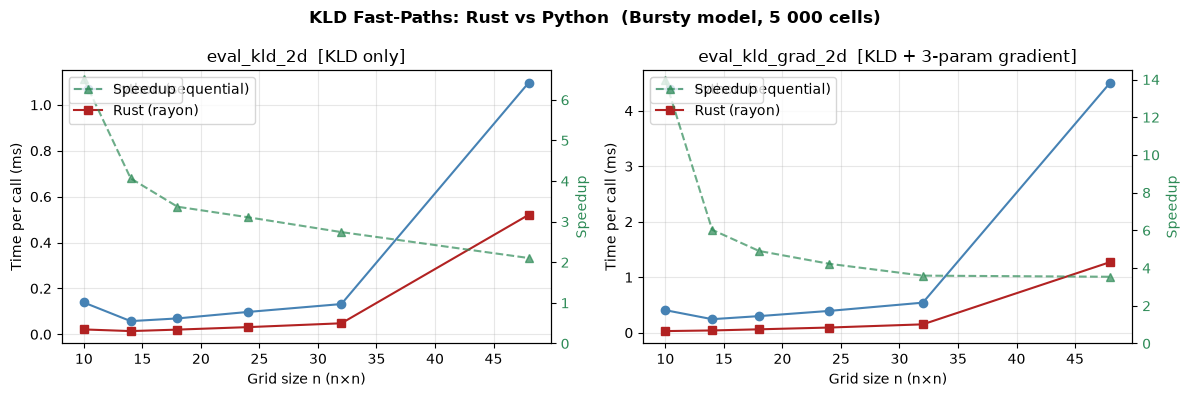

Saved kld_fastpaths.png


In [8]:
# ── Plot: KLD and KLD+grad speedup across grid sizes ─────────────────────────
grid_sizes = [10, 14, 18, 24, 32, 48]
py_kld_t, ru_kld_t, py_grad_t, ru_grad_t = [], [], [], []
N_G = 100

for gs in grid_sizes:
    lims = [gs, gs]
    u, s, f, lim = make_gene(P_REF, lims, n_cells=5000, rng=np.random.default_rng(0))
    x_a = np.column_stack([u, s]).astype(int)
    f_a = np.array(f)

    t0 = time.perf_counter()
    for _ in range(N_G):
        pss = model.eval_model_pss(np.array(P_REF), lims); np.clip(pss, EPS, None, out=pss)
        _ = float(np.sum(f_a * np.log(f_a / pss[x_a[:,0], x_a[:,1]])))
    py_kld_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = _mc.eval_kld_2d(BIO_MODEL, P_REF, lim, u, s, f, FIXED_QUAD_T, QUAD_ORDER)
    ru_kld_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = py_kld_grad(P_REF, lims, u, s, f)
    py_grad_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, lim, u, s, f, FIXED_QUAD_T, QUAD_ORDER)
    ru_grad_t.append((time.perf_counter()-t0)/N_G*1e3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, py_t, ru_t, title, note in [
    (axes[0], py_kld_t,  ru_kld_t,  "eval_kld_2d",      "KLD only"),
    (axes[1], py_grad_t, ru_grad_t, "eval_kld_grad_2d", "KLD + 3-param gradient"),
]:
    ax.plot(grid_sizes, py_t, 'o-', color=C_PY,   label="Python (sequential)")
    ax.plot(grid_sizes, ru_t, 's-', color=C_RUST,  label="Rust (rayon)")
    ax.set_xlabel("Grid size n (n×n)")
    ax.set_ylabel("Time per call (ms)")
    ax.set_title(f"{title}  [{note}]")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax2 = ax.twinx()
    ax2.plot(grid_sizes, [p/r for p,r in zip(py_t, ru_t)], '^--',
             color="seagreen", alpha=0.7, label="Speedup")
    ax2.set_ylabel("Speedup", color="seagreen")
    ax2.tick_params(axis='y', labelcolor='seagreen')
    ax2.set_ylim(bottom=0)
    ax2.legend(loc="upper left")

fig.suptitle("KLD Fast-Paths: Rust vs Python  (Bursty model, 5 000 cells)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.savefig("figures/kld_fastpaths.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved kld_fastpaths.png")

---
## 2  Rust L-BFGS-B

The Rust L-BFGS-B runs the **entire optimization loop** (L-BFGS two-loop recursion
+ More'-Thuente line search + box projection) in Rust with rayon outer
parallelism over genes.  `optimize_genes_2d_sd` reads the histograms straight
from a Rust `SearchData`, the container `searchdata_from_adata` builds, so there
are no Python callbacks, no GIL acquisition per optimizer iteration and no
marshalling of per-gene arrays.  Its ambient, protein and custom-network
variants share the solver.

The line search is a port of scipy's Fortran `dcsrch` (More'-Thuente, strong
Wolfe conditions); the search direction is the L-BFGS-B subspace step computed
with dense linear algebra, which is exact for the handful of parameters these
models have.  From the same start the two optimizers reach the same minimum;
the standalone solver tests in `monod_core/lbfgsb_rs_pure_patched/tests`
match scipy's iteration counts on Rosenbrock and quadratic problems.

A note on the status summary the optimizer logs: many genes end
with "stopped at the precision of the finite-difference gradient".  That is
the normal end point when the gradient is a forward difference, and the same
condition scipy reports as `ABNORMAL_TERMINATION_IN_LNSRCH`; the returned
point is the best one found.  Only genes that hit `max_iterations` are a
reason to raise it.

* The default since 0.4.0 (`gradient_params["use_rust_lbfgsb"] = "auto"`); `False` selects scipy.

### 2a  One gene

Replaces `scipy.optimize.minimize(..., method='L-BFGS-B')` with multiple restarts;
here on a one-gene `SearchData` holding the reference gene.

For a single gene this is not where the Rust solver wins: it computes each gene's
FD gradient sequentially inside one worker (the parallelism is over genes), while
the scipy loop below is driven by `eval_kld_grad_2d`, which spreads the
perturbations over rayon.  Section 2b is the case the solver is built for.

In [9]:
# ── API example: optimize_genes_2d_sd ─────────────────────────────────────────
#
#  params, klds = _mc.optimize_genes_2d_sd(
#      sd,                 # Rust SearchData (searchdata_from_adata / searchdata_from_arrays)
#      bio_model,          # "Bursty", "Constitutive", "CIR", "Extrinsic", "Delay", "DelayedSplicing"
#      x0_list,            # starting points, n_genes × num_restarts × n_params (log10)
#      lb, ub,             # box bounds (log10 scale), shared by all genes
#      fixed_quad_t,       # quadrature time scale
#      quad_order,         # number of GL quadrature points
#      fd_eps=1e-6,        # finite-difference step in log10 space
#      maxiter=1000,       # max L-BFGS-B iterations per restart
#      ftol=1e-10,         # relative function-improvement convergence
#      gtol=1e-6,          # projected gradient inf-norm convergence
#      base_samp=None,     # [log10_lam0, log10_lam1] for seq_model="Poisson"
#      eps=1e-15,          # probability floor
#      m_lbfgs=10,         # L-BFGS memory size
#      num_threads=None,   # rayon thread count; None = all cores
#      seq_model="Poisson",
#  ) -> (params: list[list[float]], klds: list[float])

X0_3 = [[-0.6, -0.4, -1.0], [0.0, 0.0, 0.0], [-1.5, -1.0, -1.5]]
SD_REF, _, _, _ = make_sd([P_REF], LIMITS, n_cells=5000, rng=np.random.default_rng(7))

(x_rust,), (kld_rust,) = _mc.optimize_genes_2d_sd(
    SD_REF, BIO_MODEL, [X0_3], LB, UB, FIXED_QUAD_T, QUAD_ORDER,
    fd_eps=FD_EPS, maxiter=500, ftol=1e-10, gtol=1e-6, seq_model="None",
)

print(f"Rust L-BFGS-B: kld = {kld_rust:.8f}")
print(f"               x   = {[f'{v:.4f}' for v in x_rust]}")
print(f"               true  = {P_REF}")


Rust L-BFGS-B: kld = 0.00622427
               x   = ['-0.8254', '-0.5214', '-1.2223']
               true  = [-0.8, -0.5, -1.2]


In [10]:
# ── Compare to scipy L-BFGS-B (same starting points, same FD gradient) ────────
def scipy_optimize_gene(u, s, f, limits, x0_list):
    """scipy L-BFGS-B with Rust KLD+grad callback."""
    best_kld, best_x = np.inf, None
    lim = [int(v) for v in limits]
    def obj_grad(p):
        kld, g = _mc.eval_kld_grad_2d(BIO_MODEL, list(p), lim, u, s, f,
                                       FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)
        return kld, np.array(g)
    for x0 in x0_list:
        res = scipy.optimize.minimize(obj_grad, x0, method="L-BFGS-B", jac=True,
                                      bounds=BOUNDS,
                                      options={"maxiter": 500, "ftol": 1e-10, "gtol": 1e-6})
        if res.fun < best_kld * 0.99:
            best_kld, best_x = res.fun, res.x
    return best_x, best_kld

x_sci, kld_sci = scipy_optimize_gene(U_REF, S_REF, F_REF, LIM_REF, X0_3)

print(f"scipy L-BFGS-B: kld = {kld_sci:.8f}")
print(f"                x   = {[f'{v:.4f}' for v in x_sci]}")
print(f"KLD difference: {abs(kld_rust - kld_sci):.2e}")

scipy L-BFGS-B: kld = 0.00622427
                x   = ['-0.8254', '-0.5214', '-1.2223']
KLD difference: 2.31e-16


In [11]:
# ── Speed benchmark ───────────────────────────────────────────────────────────
N_OPT = 30

t0 = time.perf_counter()
for _ in range(N_OPT):
    _ = _mc.optimize_genes_2d_sd(SD_REF, BIO_MODEL, [X0_3], LB, UB, FIXED_QUAD_T, QUAD_ORDER,
                                 fd_eps=FD_EPS, maxiter=500, seq_model="None", num_threads=1)
t_ru_opt = (time.perf_counter() - t0) / N_OPT * 1e3

t0 = time.perf_counter()
for _ in range(N_OPT):
    _ = scipy_optimize_gene(U_REF, S_REF, F_REF, LIM_REF, X0_3)
t_sci_opt = (time.perf_counter() - t0) / N_OPT * 1e3

print(f"Rust optimize_genes_2d_sd : {t_ru_opt:.2f} ms")
print(f"scipy L-BFGS-B            : {t_sci_opt:.2f} ms")
print(f"Speedup (single gene)     : {t_sci_opt/t_ru_opt:.2f}×")


Rust optimize_genes_2d_sd : 24.34 ms
scipy L-BFGS-B            : 17.66 ms
Speedup (single gene)     : 0.73×


### 2b  All genes at once (rayon)

One call optimizes every gene of the `SearchData` in parallel with rayon outer
parallelism.  Each gene's own FD gradient is computed sequentially within its
rayon worker (no nested rayon contention), giving near-linear scaling with CPU count.

In [12]:
# ── API example: all genes of a SearchData ────────────────────────────────────
N_GENES_DEMO = 20
rng_demo = np.random.default_rng(42)
# log10 (b, beta, gamma) drawn so that every gene's distribution fits the 24×20 grid
draw_params = lambda rng: [rng.uniform(-1.0, 0.3), rng.uniform(-0.5, 0.5), rng.uniform(-0.5, 0.5)]
p_trues = [draw_params(rng_demo) for _ in range(N_GENES_DEMO)]
SD_DEMO, _, _, _ = make_sd(p_trues, LIMITS, n_cells=3000, rng=np.random.default_rng(0))

x0_all = [[[0.0, 0.0, 0.0], [-1.0, -1.0, -1.0]] for _ in range(N_GENES_DEMO)]

params_batch, klds_batch = _mc.optimize_genes_2d_sd(
    SD_DEMO, BIO_MODEL, x0_all, LB, UB, FIXED_QUAD_T, QUAD_ORDER,
    fd_eps=FD_EPS, maxiter=500, seq_model="None",
)

print(f"Optimized {SD_DEMO.n_genes} genes.")
print(f"KLD range: [{min(klds_batch):.4f}, {max(klds_batch):.4f}]")
print(f"\nFirst 3 genes:")
for i in range(3):
    print(f"  gene {i}: true={[f'{v:.2f}' for v in p_trues[i]]}  "
          f"opt={[f'{v:.2f}' for v in params_batch[i]]}  kld={klds_batch[i]:.5f}")


Optimized 20 genes.
KLD range: [0.0017, 0.0290]

First 3 genes:
  gene 0: true=['0.01', '-0.06', '0.36']  opt=['-0.01', '-0.07', '0.34']  kld=0.01091
  gene 1: true=['-0.09', '-0.41', '0.48']  opt=['-0.09', '-0.40', '0.47']  kld=0.01021
  gene 2: true=['-0.01', '0.29', '-0.37']  opt=['0.02', '0.30', '-0.34']  kld=0.01868


In [13]:
# ── Scaling benchmark: genes × scipy-ThreadPool vs Rust-rayon ─────────────────
gene_counts_bench = [5, 10, 25, 50, 100, 200]
n_cpu = os.cpu_count() or 4

# Pre-generate 200 genes: one SearchData per gene count for the Rust path and
# the explicit per-gene histograms for the scipy path.
rng_b = np.random.default_rng(1)
p_bank = [draw_params(rng_b) for _ in range(200)]
_, coords_bank, freqs_bank, layers_bank = make_sd(p_bank, LIMITS, n_cells=2000, rng=np.random.default_rng(1))
gene_bank = [(np.asarray(cs)[:, 0].astype(np.uint64).tolist(), np.asarray(cs)[:, 1].astype(np.uint64).tolist(),
              list(fs), [int(v) for v in LIMITS]) for cs, fs in zip(coords_bank, freqs_bank)]
sd_bank = {ng: sd_from_layers([l[:, :ng] for l in layers_bank], LIMITS)[0] for ng in gene_counts_bench}

def scipy_pool_genes(n_genes):
    """scipy L-BFGS-B via ThreadPoolExecutor (8 workers max)."""
    data = gene_bank[:n_genes]
    def opt_one(gi):
        u, s, f, lim = data[gi]
        return scipy_optimize_gene(u, s, f, lim, [p_bank[gi], [0,0,0]])
    n_workers = min(8, n_genes, n_cpu)
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        return list(pool.map(opt_one, range(n_genes)))

def rust_batch_genes(n_genes):
    """Rust L-BFGS-B via optimize_genes_2d_sd (rayon) on the first n_genes genes."""
    x0s = [[p_bank[gi], [0,0,0]] for gi in range(n_genes)]
    return _mc.optimize_genes_2d_sd(
        sd_bank[n_genes], BIO_MODEL, x0s, LB, UB, FIXED_QUAD_T, QUAD_ORDER,
        fd_eps=FD_EPS, maxiter=500, seq_model="None",
    )

sci_times, ru_times = [], []
for ng in gene_counts_bench:
    t0 = time.perf_counter(); scipy_pool_genes(ng); t_sci = time.perf_counter()-t0
    t0 = time.perf_counter(); rust_batch_genes(ng); t_ru  = time.perf_counter()-t0
    sci_times.append(t_sci * 1e3)
    ru_times.append(t_ru  * 1e3)
    print(f"  {ng:>4} genes  scipy={t_sci*1e3:7.1f} ms  rust={t_ru*1e3:7.1f} ms  "
          f"speedup={t_sci/t_ru:.2f}×")


     5 genes  scipy=   54.5 ms  rust=   18.0 ms  speedup=3.03×
    10 genes  scipy=   60.0 ms  rust=   20.5 ms  speedup=2.92×


    25 genes  scipy=  180.2 ms  rust=   26.6 ms  speedup=6.78×


    50 genes  scipy=  284.3 ms  rust=   32.7 ms  speedup=8.68×


   100 genes  scipy=  604.1 ms  rust=   65.4 ms  speedup=9.24×


   200 genes  scipy= 1140.0 ms  rust=  107.1 ms  speedup=10.65×


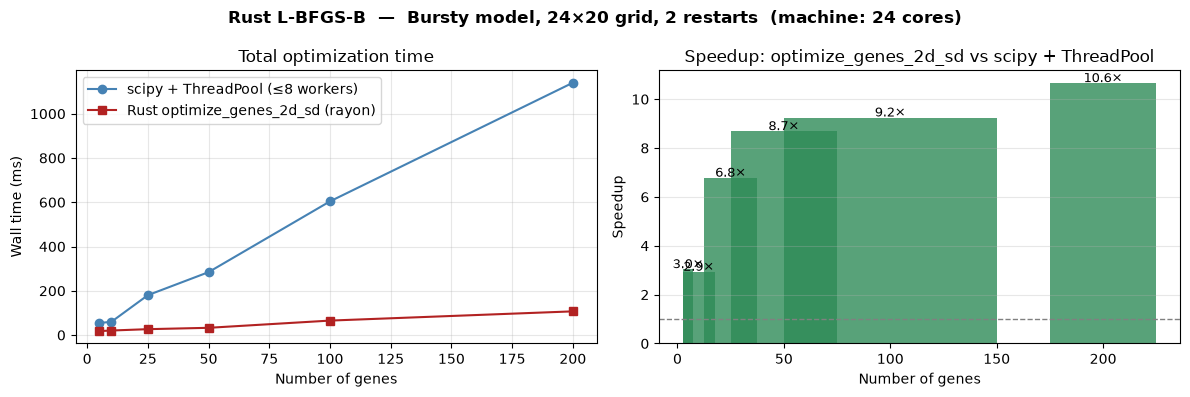

Saved rust_lbfgsb_scaling.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(gene_counts_bench, sci_times, 'o-', color=C_PY,  label=f"scipy + ThreadPool (≤8 workers)")
ax.plot(gene_counts_bench, ru_times,  's-', color=C_RUST, label="Rust optimize_genes_2d_sd (rayon)")
ax.set_xlabel("Number of genes")
ax.set_ylabel("Wall time (ms)")
ax.set_title("Total optimization time")
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
speedups = [s/r for s, r in zip(sci_times, ru_times)]
ax.bar(gene_counts_bench, speedups, color="seagreen", alpha=0.8, width=np.diff(gene_counts_bench+[250]).tolist())
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set_xlabel("Number of genes")
ax.set_ylabel("Speedup")
ax.set_title("Speedup: optimize_genes_2d_sd vs scipy + ThreadPool")
ax.grid(True, alpha=0.3, axis="y")
for xi, yi in zip(gene_counts_bench, speedups):
    ax.text(xi, yi + 0.05, f"{yi:.1f}×", ha="center", fontsize=9)

fig.suptitle(f"Rust L-BFGS-B  —  Bursty model, 24×20 grid, 2 restarts  (machine: {n_cpu} cores)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.savefig("figures/rust_lbfgsb_scaling.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved rust_lbfgsb_scaling.png")

---
## 3  Inference pipeline flags

The optimizer options are passed through `gradient_params` when constructing
`InferenceParameters`:

```python
from monod.inference import InferenceParameters

ip = InferenceParameters(
    dataset_string, model,
    phys_lb=[-3, -3, -3], phys_ub=[3, 3, 3],
    gradient_params={
        "max_iterations": 200,        # L-BFGS-B steps per restart
        "num_restarts":   3,          # independent restarts, best KLD kept
        "init_pattern":   "moments",  # first restart from the method-of-moments estimate

        # scipy path: genes in parallel through a ThreadPoolExecutor
        #   1 = one gene at a time (default), N = N threads, -1 = all cores
        "num_gene_cores": 1,

        # "auto" (default): the whole fit runs in the Rust L-BFGS-B kernel
        # whenever the extension and a Rust SearchData (hist_type="unique",
        # quad_method="fixed_quad") are available; genes run in parallel under
        # rayon, where num_gene_cores of 1 or -1 means all cores and N > 1 caps
        # the thread count at N.  False selects scipy.  Covers the 2-D models
        # with and without sequencing noise, the ambiguous-assignment models,
        # the protein model and custom networks.
        "use_rust_lbfgsb": "auto",
    },
)
```

The rest of the notebook times these modes on PBMC 10k.  The data are loaded once
here: the first 1000 genes seen in at least 10 cells, with their unique
histograms extracted once and subset as needed (the per-gene grid limits live in
`var`, so an AnnData gene subset keeps them).


In [15]:
# ── PBMC 10k: load once, pick the gene pool for sections 3–5 ─────────────────
H5AD_PATH  = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
PBMC_MODEL = CMEModel('Bursty', 'Poisson')

t0 = time.perf_counter()
adata_pbmc = ad.read_h5ad(H5AD_PATH)
print(f'read_h5ad: {time.perf_counter() - t0:.1f} s  |  {adata_pbmc.n_obs} cells × {adata_pbmc.n_vars} genes')

# Genes seen in at least 10 cells, counted on the sparse matrix; the first 1000 in
# file order are a mix of expression levels.
expressed = select_expressed_genes(adata_pbmc, min_cells=10)
pool_rank = expressed[:1000]

# Unique histograms for the whole pool, extracted once; later sections subset them.
t0 = time.perf_counter()
adata_pool = extract_data(
    adata_pbmc, PBMC_MODEL, dataset_name='pbmc_bench',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=len(pool_rank), genes_to_fit=pool_rank, hist_type='unique', viz=False,
)
kept = set(adata_pool.var_names)
GENE_POOL = [g for g in pool_rank if g in kept]
print(f'extract_data: {time.perf_counter() - t0:.1f} s  |  gene pool: {len(GENE_POOL)} genes '
      f'(of {len(expressed)} seen in ≥10 cells)')


def make_ip(extra_gp, gridsize=(1, 1), max_iter=50, num_restarts=3):
    """InferenceParameters for the PBMC fits; extra_gp overrides the optimizer flags."""
    gp = {'max_iterations': max_iter, 'init_pattern': 'moments',
          'num_restarts': num_restarts, **extra_gp}
    return InferenceParameters('pbmc_bench', PBMC_MODEL, use_lengths=False,
                               gradient_params=gp, gridsize=list(gridsize), save=False)


def time_fit(sd, extra_gp, **kw):
    """Wall time (ms) of fit_all_grid_points on a SearchData."""
    ip = make_ip(extra_gp, **kw)
    t0 = time.perf_counter()
    ip.fit_all_grid_points(sd, num_cores=1, save=False)
    return (time.perf_counter() - t0) * 1e3


# The three optimizer modes compared in sections 3 and 4.1.  The Rust KLD kernels
# of section 1 are active in all three; only the optimizer differs.
OPT_MODES = {
    'Serial scipy':       {'num_gene_cores': 1,  'use_rust_lbfgsb': False},
    'scipy + ThreadPool': {'num_gene_cores': -1, 'use_rust_lbfgsb': False},
    'Rust L-BFGS-B':      {'num_gene_cores': -1, 'use_rust_lbfgsb': 'auto'},
}


read_h5ad: 0.4 s  |  10997 cells × 36601 genes


extract_data: 5.0 s  |  gene pool: 1000 genes (of 16244 seen in ≥10 cells)


In [16]:
# ── Live demo: the three optimizer modes on 50 PBMC genes ─────────────────────
GENES_50 = GENE_POOL[:50]
sd_50 = searchdata_from_adata(adata_pool[:, GENES_50].copy())   # subsets keep their grid limits
print(f'SearchData: {sd_50.n_genes} genes  |  1×1 grid, 50 iterations, 3 restarts\n')
print(f"{'Mode':<22} {'Time (ms)':>10}")
print('-' * 34)
times_inf = {}
for label, gp in OPT_MODES.items():
    times_inf[label] = time_fit(sd_50, gp)
    print(f'{label:<22} {times_inf[label]:10.0f}')


SearchData: 50 genes  |  1×1 grid, 50 iterations, 3 restarts

Mode                    Time (ms)
----------------------------------


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.46s/it]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.46s/it]

Serial scipy                 2468


...

scipy + ThreadPool           1001


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.53it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.51it/s]

Rust L-BFGS-B                 287


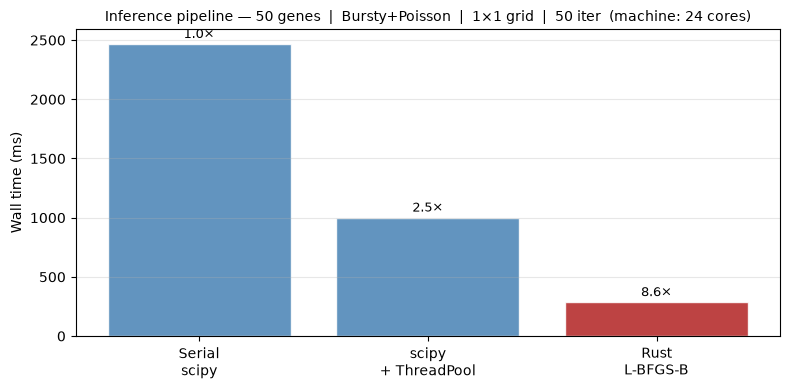

In [17]:
# ── Plot: inference mode comparison ──────────────────────────────────────────
labels_inf = ["Serial\nscipy", "scipy\n+ ThreadPool", "Rust\nL-BFGS-B"]
vals_inf   = list(times_inf.values())
t_serial   = times_inf['Serial scipy']

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels_inf, vals_inf, color=[C_PY, C_PY, C_RUST], alpha=0.85, edgecolor="white")
ax.set_ylabel("Wall time (ms)")
ax.set_title(f"Inference pipeline — {len(GENES_50)} genes  |  Bursty+Poisson  |  1×1 grid  |  50 iter  "
             f"(machine: {n_cpu} cores)", fontsize=10)
ax.grid(True, alpha=0.3, axis="y")
for bar, t in zip(bars, vals_inf):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals_inf)*0.01,
            f"{t_serial/t:.1f}×", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.savefig("figures/inference_modes.png", dpi=120, bbox_inches="tight")
plt.show()


---
## 4  Scaling on PBMC 10k

Section 4.1 varies the gene count for the three optimizer modes of section 3; the
Rust KLD kernels of section 1 are active in all three, so this isolates the
optimizer.  Sections 4.2 and 4.3 vary the core count and the cell count for the
package with the extension switched off (numba model evaluation, scipy L-BFGS-B)
against the defaults with it on, so they measure what installing the extension
buys for a fit.  The loading path is timed in `rust_pipeline.ipynb`.

Settings: Bursty + Poisson throughout.  4.1 uses a 1×1 grid, 50 iterations and 3
restarts on 50–1000 genes; 4.2 and 4.3 use the 3×4 sampling grid (12 points), 10
iterations and 1 restart on 50 genes, which keeps the Python runs short.


### 4.1  Gene count


In [18]:
# ── Gene-count sweep: the three optimizer modes, 50 – 1000 genes ─────────────
GENE_COUNTS = [n for n in (50, 100, 200, 500, 1000) if n <= len(GENE_POOL)]
gene_sweep  = {label: [] for label in OPT_MODES}

for n in GENE_COUNTS:
    sd_n = searchdata_from_adata(adata_pool[:, GENE_POOL[:n]].copy())
    for label, gp in OPT_MODES.items():
        gene_sweep[label].append(time_fit(sd_n, gp))
    t_s, t_t, t_r = (gene_sweep[label][-1] for label in OPT_MODES)
    print(f'n={n:4d}:  serial {t_s:7.0f} ms  |  threads {t_t:7.0f} ms  |  rust {t_r:7.0f} ms  '
          f'(rust speedup vs serial: {t_s/t_r:.1f}×)')
    del sd_n; gc.collect()


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.02s/it]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.02s/it]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.20s/it]

...

Grid scan: 100%|██████████| 1/1 [03:00<00:00, 180.47s/it]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:03<00:00,  3.23s/it]

Grid scan: 100%|██████████| 1/1 [00:03<00:00,  3.23s/it]

n=1000:  serial  123252 ms  |  threads  180474 ms  |  rust    3232 ms  (rust speedup vs serial: 38.1×)


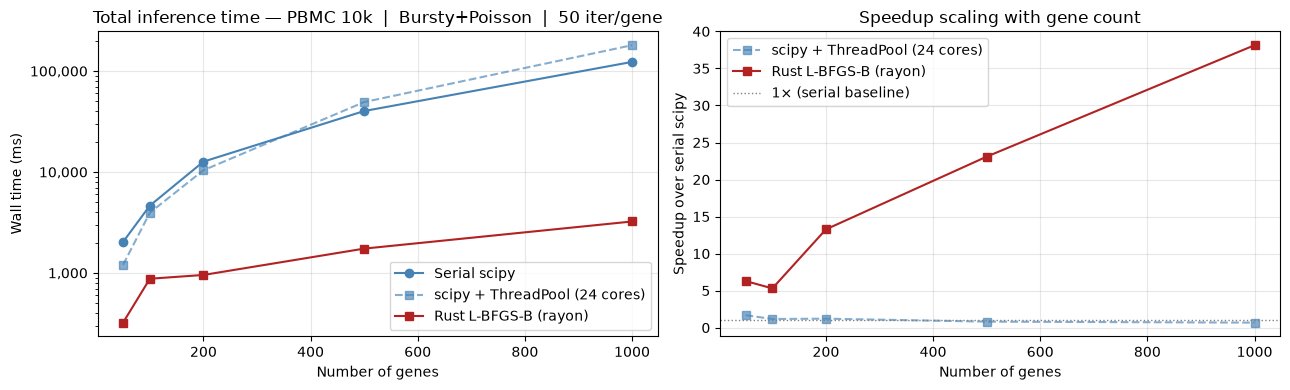


 Genes   Serial (ms)   ThreadPool (ms)   Rust (ms)   Rust speedup   Threads speedup
--------------------------------------------------------------------------------
    50          2026              1201         322           6.3×              1.7×
   100          4642              3950         875           5.3×              1.2×
   200         12663             10401         954          13.3×              1.2×
   500         40188             49297        1740          23.1×              0.8×
  1000        123252            180474        3232          38.1×              0.7×


In [19]:
# ── Plot: wall time + speedup vs serial ──────────────────────────────────────
res_serial, res_threads, res_rust = (gene_sweep[label] for label in OPT_MODES)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(GENE_COUNTS, res_serial,  'o-',  color=C_PY,             label='Serial scipy')
ax.plot(GENE_COUNTS, res_threads, 's--', color=C_PY, alpha=0.65, label=f'scipy + ThreadPool ({n_cpu} cores)')
ax.plot(GENE_COUNTS, res_rust,    's-',  color=C_RUST,           label='Rust L-BFGS-B (rayon)')
ax.set_xlabel('Number of genes'); ax.set_ylabel('Wall time (ms)')
ax.set_title('Total inference time — PBMC 10k  |  Bursty+Poisson  |  50 iter/gene')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(); ax.grid(True, alpha=0.3)

ax2 = axes[1]
ax2.plot(GENE_COUNTS, [s / t for s, t in zip(res_serial, res_threads)], 's--', color=C_PY, alpha=0.65,
         label=f'scipy + ThreadPool ({n_cpu} cores)')
ax2.plot(GENE_COUNTS, [s / r for s, r in zip(res_serial, res_rust)], 's-', color=C_RUST,
         label='Rust L-BFGS-B (rayon)')
ax2.axhline(1, color='grey', linestyle=':', linewidth=1, label='1× (serial baseline)')
ax2.set_xlabel('Number of genes'); ax2.set_ylabel('Speedup over serial scipy')
ax2.set_title('Speedup scaling with gene count')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/pbmc_gene_sweep.png', dpi=150)
plt.show()

print(f'\n{"Genes":>6}  {"Serial (ms)":>12}  {"ThreadPool (ms)":>16}  '
      f'{"Rust (ms)":>10}  {"Rust speedup":>13}  {"Threads speedup":>16}')
print('-' * 80)
for n, ts, tt, tr in zip(GENE_COUNTS, res_serial, res_threads, res_rust):
    print(f'{n:6d}  {ts:12.0f}  {tt:16.0f}  {tr:10.0f}  {ts/tr:12.1f}×  {ts/tt:15.1f}×')


### 4.2  Core count, with and without the extension

With the extension off, `num_gene_cores` sets the width of the scipy thread pool;
the threads share the GIL outside the numba kernels, so the scaling is poor.  With
it on, `num_gene_cores` caps the rayon thread count; 1 and -1 both mean all cores,
so the Rust series starts at 2.


In [20]:
# ── Core-count sweep: extension off vs on, 50 genes, 3×4 grid, 10 iterations ─
def time_fit_ext(sd, rust_on, n_cores, gridsize=(3, 4), max_iter=10, num_restarts=1):
    """time_fit with the extension switched off (numba model evaluation + scipy
    L-BFGS-B) or on (the defaults: Rust kernels + Rust L-BFGS-B)."""
    cme_toolbox._HAS_RUST = rust_on
    gp = {'num_gene_cores': n_cores, 'use_rust_lbfgsb': 'auto' if rust_on else False}
    try:
        return time_fit(sd, gp, gridsize=gridsize, max_iter=max_iter, num_restarts=num_restarts)
    finally:
        cme_toolbox._HAS_RUST = _HAS_RUST


CORE_COUNTS = sorted({1, 2, 4, 8, n_cpu})
core_sweep  = {}
for nc in CORE_COUNTS:
    for rust_on in (False, True):
        if rust_on and nc == 1:
            continue        # num_gene_cores=1 means all cores for the Rust kernel
        t = time_fit_ext(sd_50, rust_on, nc)
        core_sweep[(nc, rust_on)] = t
        print(f'cores={nc:2d}  {"Rust  " if rust_on else "Python"}  {t/1e3:6.1f} s')


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:02<00:23,  2.11s/it]

Grid scan:  17%|█▋        | 2/12 [00:04<00:21,  2.11s/it]

Grid scan:  25%|██▌       | 3/12 [00:06<00:19,  2.22s/it]

Grid scan:  33%|███▎      | 4/12 [00:09<00:19,  2.47s/it]

...

optimize_genes_2d_sd: 25/50 genes did not converge (25 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


optimize_genes_2d_sd: 18/50 genes did not converge (18 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 12/12 [00:01<00:00,  8.88it/s]

Grid scan: 100%|██████████| 12/12 [00:01<00:00,  7.31it/s]

cores=24  Rust       1.6 s


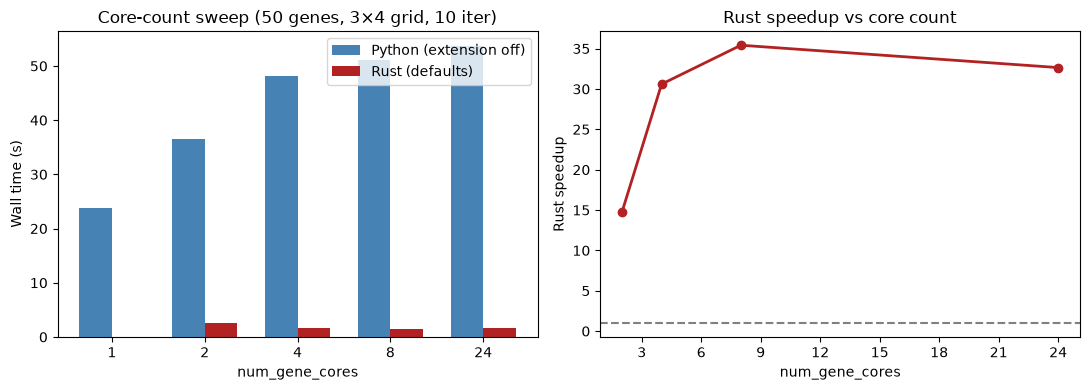

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x, w = np.arange(len(CORE_COUNTS)), 0.35
py_t = [core_sweep[(nc, False)] / 1e3 for nc in CORE_COUNTS]
ru_t = [core_sweep.get((nc, True), np.nan) / 1e3 for nc in CORE_COUNTS]

ax = axes[0]
ax.bar(x - w/2, py_t, w, label='Python (extension off)', color=C_PY)
ax.bar(x + w/2, ru_t, w, label='Rust (defaults)',        color=C_RUST)
ax.set_xticks(x); ax.set_xticklabels(CORE_COUNTS)
ax.set_xlabel('num_gene_cores'); ax.set_ylabel('Wall time (s)')
ax.set_title(f'Core-count sweep ({sd_50.n_genes} genes, 3×4 grid, 10 iter)')
ax.legend()

ax = axes[1]
ax.plot(CORE_COUNTS, [p / r for p, r in zip(py_t, ru_t)], 'o-', color=C_RUST, linewidth=2)
ax.axhline(1, linestyle='--', color='gray')
ax.set_xlabel('num_gene_cores'); ax.set_ylabel('Rust speedup')
ax.set_title('Rust speedup vs core count')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
fig.tight_layout()
plt.savefig('figures/pbmc_core_sweep.png', dpi=120, bbox_inches='tight')
plt.show()


### 4.3  Cell count, with and without the extension

The same 50 genes on random subsets of the cells, with the defaults on both sides
(scipy one gene at a time; Rust on all cores).  More cells mean denser histograms
and larger PSS grids; the top axis of the right panel shows the median grid size.


In [22]:
# ── Cell-count sweep: extension off vs on, defaults, 50 genes ────────────────
CELL_COUNTS = [100, 500, 1000, 10000]
rng = np.random.default_rng(0)
cell_sweep  = {}   # (n_cells, rust_on) -> wall time (ms)
median_grid = {}   # n_cells -> median PSS grid size

for n_cells in CELL_COUNTS:
    idx = np.sort(rng.choice(adata_pbmc.n_obs, size=min(n_cells, adata_pbmc.n_obs), replace=False))
    adata_cells = extract_data(
        adata_pbmc[idx].copy(), PBMC_MODEL, dataset_name='pbmc_bench',
        modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
        n_genes=len(GENES_50), genes_to_fit=GENES_50, hist_type='unique', viz=False,
    )
    M = grid_limits(adata_cells)
    median_grid[n_cells] = int(np.median(M[0] * M[1]))
    sd_cells = searchdata_from_adata(adata_cells)
    for rust_on in (False, True):
        t = time_fit_ext(sd_cells, rust_on, n_cores=1)
        cell_sweep[(n_cells, rust_on)] = t
        print(f'cells={n_cells:5d}  genes={sd_cells.n_genes}  median grid={median_grid[n_cells]:4d}  '
              f'{"Rust  " if rust_on else "Python"}  {t/1e3:6.1f} s')
    del adata_cells, sd_cells; gc.collect()


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:15,  1.45s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:14,  1.40s/it]

Grid scan:  25%|██▌       | 3/12 [00:04<00:12,  1.44s/it]

Grid scan:  33%|███▎      | 4/12 [00:05<00:12,  1.50s/it]

...

optimize_genes_2d_sd: 25/50 genes did not converge (25 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan:  92%|█████████▏| 11/12 [00:01<00:00,  7.40it/s]

optimize_genes_2d_sd: 20/50 genes did not converge (20 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 12/12 [00:01<00:00,  6.89it/s]

cells=10000  genes=50  median grid= 224  Rust       1.7 s


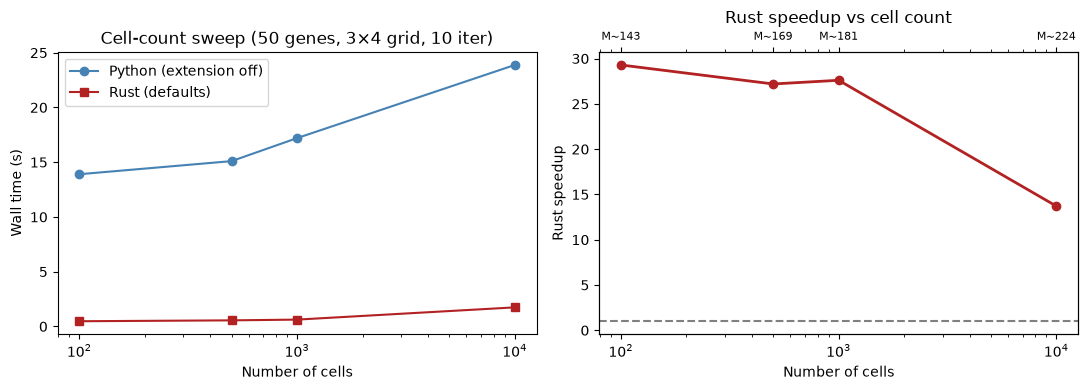

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cr_py   = [cell_sweep[(n, False)] / 1e3 for n in CELL_COUNTS]
cr_rust = [cell_sweep[(n, True)]  / 1e3 for n in CELL_COUNTS]

ax = axes[0]
ax.plot(CELL_COUNTS, cr_py,   'o-', color=C_PY,   label='Python (extension off)')
ax.plot(CELL_COUNTS, cr_rust, 's-', color=C_RUST, label='Rust (defaults)')
ax.set_xscale('log')
ax.set_xlabel('Number of cells'); ax.set_ylabel('Wall time (s)')
ax.set_title(f'Cell-count sweep ({len(GENES_50)} genes, 3×4 grid, 10 iter)')
ax.legend()

ax = axes[1]
ax.set_xscale('log')
ax.plot(CELL_COUNTS, [p / r for p, r in zip(cr_py, cr_rust)], 'o-', color=C_RUST, linewidth=2)
ax.axhline(1, linestyle='--', color='gray')
ax2 = ax.twiny()
ax2.set_xscale('log')
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks(CELL_COUNTS)
ax2.set_xticklabels([f'M~{median_grid[n]}' for n in CELL_COUNTS], fontsize=8)
ax.set_xlabel('Number of cells'); ax.set_ylabel('Rust speedup')
ax.set_title('Rust speedup vs cell count')
fig.tight_layout()
plt.savefig('figures/pbmc_cell_sweep.png', dpi=120, bbox_inches='tight')
plt.show()


---
## 5  Concordance: scipy against the Rust kernel

Speed is worth nothing if the optimizers disagree.  Here both fit the same 50
PBMC genes on the 3×4 sampling grid with 200 iterations and three restarts;
`np.random.seed` is reset before each run so the two draw identical random
restarts, and every grid point is compared, not only the sampling optimum.

The two implement the same algorithm (L-BFGS-B with a Moré–Thuente line search)
on the same objective, so they should reach the same minima.  Where the
parameters still differ, the KLDs tell whether one optimizer failed (different
KLD) or the likelihood is flat along some direction (the same KLD at different
parameters).  Both start every gene at every grid point from the same moments
estimate; grid points are not warm-started from their neighbours.

Panel A compares the best KLD per gene; B plots the KLD difference against the
parameter difference for every gene × grid-point pair; C counts the pairs with a
large parameter difference by whether the KLD moved.


Optimizer concordance: 50 genes, 3×4 grid, 200 iterations, 3 restarts


Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:13,  1.20s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:12,  1.22s/it]

Grid scan:  25%|██▌       | 3/12 [00:03<00:09,  1.10s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:02<00:00,  3.86it/s]

Grid scan:  92%|█████████▏| 11/12 [00:03<00:00,  4.04it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  4.42it/s]

Grid scan: 100%|██████████| 12/12 [00:03<00:00,  3.71it/s]

  Rust:   3.2 s  (3.6× faster)


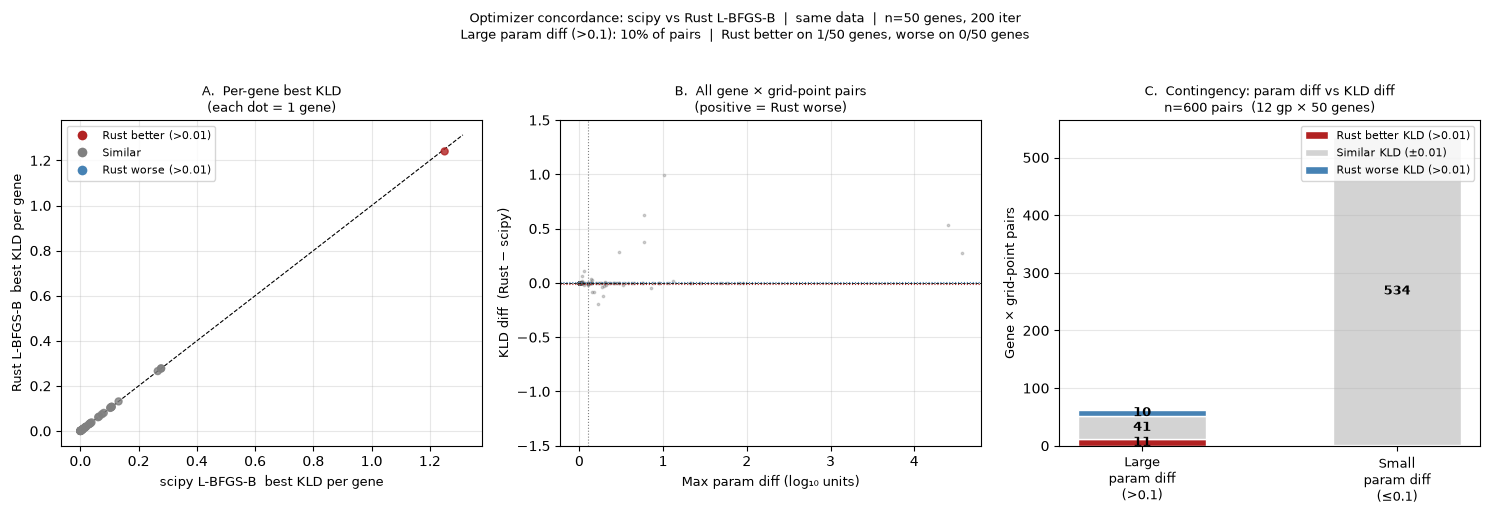


Optimizer concordance summary  (12 gp x 50 genes = 600 pairs):
  Large param diff (>0.1 log10):    62 / 600  (10%)
    of which Rust better KLD:   11  (2% of total)
    of which KLD similar:       41  ← flat landscape
    of which Rust worse KLD:    10
  Rust finds better per-gene min-KLD: 1/50 genes  (mean delta=-0.000)
  Rust finds worse  per-gene min-KLD: 0/50 genes


In [24]:
# ── Optimizer concordance: scipy vs Rust L-BFGS-B on the same data ───────────
N_OPT_GENES   = 50
OPT_CONC_SEED = 42        # same random restarts for both optimizers
N_OPT_ITER    = 200
N_RESTARTS    = 3
GRID_CONC     = (3, 4)
sd_opt = searchdata_from_adata(adata_pool[:, GENE_POOL[:N_OPT_GENES]].copy())


def run_opt(use_rust):
    """(param_estimates [n_gp, n_genes, 3], klds [n_gp, n_genes], seconds)."""
    gp = {'num_gene_cores': -1, 'use_rust_lbfgsb': 'auto' if use_rust else False}
    ip = make_ip(gp, gridsize=GRID_CONC, max_iter=N_OPT_ITER, num_restarts=N_RESTARTS)
    t0 = time.perf_counter()
    result = ip.fit_all_grid_points(sd_opt, num_cores=1, save=False)
    return result.param_estimates.copy(), result.klds.copy(), time.perf_counter() - t0


print(f'Optimizer concordance: {N_OPT_GENES} genes, {GRID_CONC[0]}×{GRID_CONC[1]} grid, '
      f'{N_OPT_ITER} iterations, {N_RESTARTS} restarts')
np.random.seed(OPT_CONC_SEED)
p_sc, k_sc, t_sc = run_opt(use_rust=False)
print(f'  scipy:  {t_sc:.1f} s')
np.random.seed(OPT_CONC_SEED)
p_ru, k_ru, t_ru = run_opt(use_rust=True)
print(f'  Rust:   {t_ru:.1f} s  ({t_sc/t_ru:.1f}× faster)')

# ── Classification ────────────────────────────────────────────────────────
n_gp_opt, n_gene_opt, _ = p_sc.shape
kld_diff  = k_ru - k_sc                          # positive = Rust worse
max_pdiff = np.abs(p_sc - p_ru).max(axis=2)      # (n_gp, n_genes)

PDIFF_T = 0.1    # log10
KLD_T   = 0.01   # KLD units

large_p   = max_pdiff > PDIFF_T
ru_worse  = kld_diff  >  KLD_T
ru_better = kld_diff  < -KLD_T
ru_same   = ~ru_worse & ~ru_better

k_sc_best = k_sc.min(axis=0)
k_ru_best = k_ru.min(axis=0)
delta     = k_ru_best - k_sc_best

# ── Figure ────────────────────────────────────────────────────────────────
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Panel A: per-gene best KLD scatter
ax = axes[0]
c_gene = np.where(delta < -KLD_T, C_RUST, np.where(delta > KLD_T, C_PY, 'grey'))
ax.scatter(k_sc_best, k_ru_best, c=c_gene, s=25, alpha=0.8, zorder=3)
lo = min(k_sc_best.min(), k_ru_best.min()) * 0.95
hi = max(k_sc_best.max(), k_ru_best.max()) * 1.05
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
ax.legend(handles=[
    Line2D([0], [0], marker='o', color='w', markerfacecolor=C_RUST, ms=8, label=f'Rust better (>{KLD_T})'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='grey', ms=8, label='Similar'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=C_PY,   ms=8, label=f'Rust worse (>{KLD_T})'),
], fontsize=8)
ax.set_xlabel('scipy L-BFGS-B  best KLD per gene', fontsize=9)
ax.set_ylabel('Rust L-BFGS-B  best KLD per gene', fontsize=9)
ax.set_title('A.  Per-gene best KLD\n(each dot = 1 gene)', fontsize=9)
ax.grid(True, alpha=0.3)

# Panel B: KLD diff vs param diff (all gene × grid-point pairs)
ax = axes[1]
ax.axhline(0, color='k', lw=0.6, ls='--')
ax.axhline( KLD_T, color=C_PY,   lw=0.8, ls=':')
ax.axhline(-KLD_T, color=C_RUST, lw=0.8, ls=':')
ax.axvline(PDIFF_T, color='grey', lw=0.8, ls=':')
ax.scatter(max_pdiff.ravel(), kld_diff.ravel(), s=3, alpha=0.25, color='#555555', rasterized=True)
ax.set_xlabel('Max param diff (log₁₀ units)', fontsize=9)
ax.set_ylabel('KLD diff  (Rust − scipy)', fontsize=9)
ax.set_title('B.  All gene × grid-point pairs\n(positive = Rust worse)', fontsize=9)
ax.set_ylim(-1.5, 1.5)
ax.grid(True, alpha=0.3)

# Panel C: contingency stacked bar
ax = axes[2]
groups = ['Large\nparam diff\n(>0.1)', 'Small\nparam diff\n(≤0.1)']
mask_large = large_p.ravel()
mask_small = ~mask_large

def _counts(mask):
    return [(mask & ru_better.ravel()).sum(),
            (mask & ru_same.ravel()).sum(),
            (mask & ru_worse.ravel()).sum()]

cnts_large = _counts(mask_large)
cnts_small = _counts(mask_small)
colors_bar = [C_RUST, 'lightgrey', C_PY]
labels_bar = [f'Rust better KLD (>{KLD_T})', f'Similar KLD (±{KLD_T})', f'Rust worse KLD (>{KLD_T})']

x_pos = np.array([0, 1])
bottoms = [0, 0]
for ci, (color, label) in enumerate(zip(colors_bar, labels_bar)):
    vals = [cnts_large[ci], cnts_small[ci]]
    ax.bar(x_pos, vals, bottom=bottoms, color=color, width=0.5, label=label, edgecolor='white')
    for xi, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 5:
            ax.text(xi, b + v/2, str(v), ha='center', va='center', fontsize=9, fontweight='bold')
    bottoms = [b + v for b, v in zip(bottoms, vals)]

ax.set_xticks(x_pos)
ax.set_xticklabels(groups, fontsize=9)
ax.set_ylabel('Gene × grid-point pairs', fontsize=9)
ax.set_title('C.  Contingency: param diff vs KLD diff\n'
             f'n={n_gp_opt * N_OPT_GENES} pairs  ({n_gp_opt} gp × {N_OPT_GENES} genes)', fontsize=9)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle(
    f'Optimizer concordance: scipy vs Rust L-BFGS-B  |  same data  |  '
    f'n={N_OPT_GENES} genes, {N_OPT_ITER} iter\n'
    f'Large param diff (>{PDIFF_T}): {100*large_p.mean():.0f}% of pairs  |  '
    f'Rust better on {(delta < -KLD_T).sum()}/{N_OPT_GENES} genes, '
    f'worse on {(delta > KLD_T).sum()}/{N_OPT_GENES} genes',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rust_opt_concordance.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ─────────────────────────────────────────────────────────
total = n_gp_opt * N_OPT_GENES
print(f'\nOptimizer concordance summary  ({n_gp_opt} gp x {N_OPT_GENES} genes = {total} pairs):')
print(f'  Large param diff (>{PDIFF_T} log10):  {large_p.sum():4d} / {total}  ({100*large_p.mean():.0f}%)')
print(f'    of which Rust better KLD: {(large_p & ru_better).sum():4d}  ({100*(large_p & ru_better).mean():.0f}% of total)')
print(f'    of which KLD similar:     {(large_p & ru_same  ).sum():4d}  ← flat landscape')
print(f'    of which Rust worse KLD:  {(large_p & ru_worse ).sum():4d}')
print(f'  Rust finds better per-gene min-KLD: {(delta < -KLD_T).sum()}/{N_OPT_GENES} genes  (mean delta={delta.mean():.3f})')
print(f'  Rust finds worse  per-gene min-KLD: {(delta >  KLD_T).sum()}/{N_OPT_GENES} genes')


### Which parameter differs

Three questions about the pairs with a large parameter difference: which
parameter (`b`, `β`, `γ`) drives them; whether the differences are small but
numerous or large and rare; and whether they cluster on particular genes
(non-convex landscapes on those genes) or on particular grid points (a regime
where one optimizer is systematically weaker).


Per-parameter: fraction of 600 pairs with |Δ| > 0.1:
  b  (burst freq): 7.2%
  β  (splicing): 7.0%
  γ  (degr.): 6.2%
  (any param):  10.3%

Per-gene disagree rate (frac of 12 gp with |Δmax|>0.1):
  mean=0.10  median=0.00  max=0.75  genes with rate>0.5: 4

Per-grid-point disagree rate (frac of 50 genes with |Δmax|>0.1):
  gp  0: 0.06
  gp  1: 0.04
  gp  2: 0.10
  gp  3: 0.38
  gp  4: 0.02
  gp  5: 0.04
  gp  6: 0.14
  gp  7: 0.20
  gp  8: 0.04
  gp  9: 0.04
  gp 10: 0.06
  gp 11: 0.12


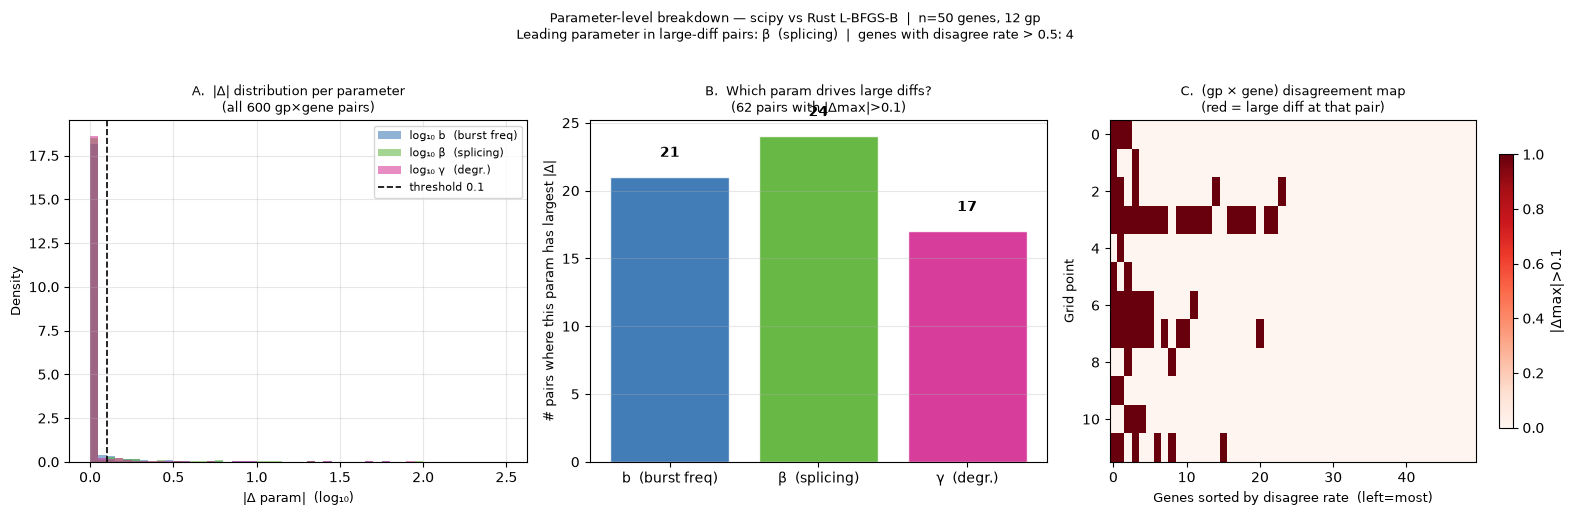

Saved figures/rust_opt_param_breakdown.png


In [25]:
# ── Per-parameter breakdown ───────────────────────────────────────────────
# pdiff_3[gp, gene, param] = |scipy_param - rust_param| for each of the 3 params
pdiff_3 = np.abs(p_sc - p_ru)   # (n_gp, n_genes, 3)
param_names_short = ['b  (burst freq)', 'β  (splicing)', 'γ  (degr.)']
param_names_full  = ['log₁₀ b  (burst freq)', 'log₁₀ β  (splicing)', 'log₁₀ γ  (degr.)']
param_colors_3    = ['#2166ac', '#4dac26', '#d01c8b']

# For each large-diff pair, which param is the worst offender?
leading_param  = pdiff_3.argmax(axis=2)          # (n_gp, n_genes) → 0/1/2
large_mask_flat = max_pdiff.ravel() > PDIFF_T    # (600,)
leading_large  = leading_param.ravel()[large_mask_flat]

# Fraction of gp where each gene disagrees (per-parameter and overall)
disagree_mat = (max_pdiff > PDIFF_T).astype(float)   # (n_gp, n_genes)
disagree_per_gene = disagree_mat.mean(0)              # (n_genes,)
disagree_per_gp   = disagree_mat.mean(1)              # (n_gp,)

print('Per-parameter: fraction of 600 pairs with |Δ| > 0.1:')
for pi, pname in enumerate(param_names_short):
    frac = (pdiff_3[:, :, pi].ravel() > PDIFF_T).mean()
    print(f'  {pname}: {frac:.1%}')
print(f'  (any param):  {large_mask_flat.mean():.1%}')

print(f'\nPer-gene disagree rate (frac of {n_gp_opt} gp with |Δmax|>0.1):')
print(f'  mean={disagree_per_gene.mean():.2f}  '
      f'median={np.median(disagree_per_gene):.2f}  '
      f'max={disagree_per_gene.max():.2f}  '
      f'genes with rate>0.5: {(disagree_per_gene>0.5).sum()}')

print(f'\nPer-grid-point disagree rate (frac of {N_OPT_GENES} genes with |Δmax|>0.1):')
for gp_i, dr in enumerate(disagree_per_gp):
    print(f'  gp {gp_i:2d}: {dr:.2f}')

# ── Figure ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel A: |Δ| distribution per parameter (overlapping histograms)
ax = axes[0]
bins = np.linspace(0, 2.5, 51)
for pi, (pname, color) in enumerate(zip(param_names_full, param_colors_3)):
    ax.hist(pdiff_3[:, :, pi].ravel(), bins=bins,
            color=color, alpha=0.5, label=pname, density=True)
ax.axvline(PDIFF_T, color='k', lw=1.2, ls='--', label=f'threshold {PDIFF_T}')
ax.set_xlabel('|Δ param|  (log₁₀)', fontsize=9)
ax.set_ylabel('Density', fontsize=9)
ax.set_title('A.  |Δ| distribution per parameter\n(all 600 gp×gene pairs)', fontsize=9)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel B: which parameter leads large-diff pairs?
ax = axes[1]
counts = np.bincount(leading_large, minlength=3)
bars = ax.bar(param_names_short, counts, color=param_colors_3, alpha=0.85, edgecolor='white')
for xi, c in enumerate(counts):
    ax.text(xi, c + 1.5, str(c), ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel(f'# pairs where this param has largest |Δ|', fontsize=9)
ax.set_title(f'B.  Which param drives large diffs?\n({large_mask_flat.sum()} pairs with |Δmax|>{PDIFF_T})', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# Panel C: (gene × gp) disagreement heatmap
ax = axes[2]
gene_order = disagree_per_gene.argsort()[::-1]   # sort genes by disagree rate desc
im = ax.imshow(disagree_mat[:, gene_order], aspect='auto', cmap='Reds',
               vmin=0, vmax=1, interpolation='nearest')
plt.colorbar(im, ax=ax, label='|Δmax|>0.1', shrink=0.8)
ax.set_xlabel(f'Genes sorted by disagree rate  (left=most)', fontsize=9)
ax.set_ylabel('Grid point', fontsize=9)
ax.set_title('C.  (gp × gene) disagreement map\n(red = large diff at that pair)', fontsize=9)

plt.suptitle(
    f'Parameter-level breakdown — scipy vs Rust L-BFGS-B  |  n={N_OPT_GENES} genes, {n_gp_opt} gp\n'
    f'Leading parameter in large-diff pairs: {param_names_short[int(np.argmax(counts))]}  |  '
    f'genes with disagree rate > 0.5: {(disagree_per_gene > 0.5).sum()}',
    fontsize=9, y=1.02,
)
plt.tight_layout()
plt.savefig('figures/rust_opt_param_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved figures/rust_opt_param_breakdown.png')

---
## Summary

The Rust fast paths, what switches them on, and the speedups measured above:


In [26]:
rows = [
    # (Function / flag, Activates automatically?, Prerequisite / flag, Speedup)
    ("eval_kld_2d",
     "Yes (auto)",
     "hist_type=unique, 2-D model, fixed_quad",
     f"{t_py_kld/t_ru_kld:.1f}× per call"),
    ("eval_kld_grad_2d",
     "Yes (auto)",
     "Same as above (FD gradient path)",
     f"{t_py_grad/t_ru_grad:.1f}× per call  (rayon over n_params+1)"),
    ("optimize_genes_2d_sd",
     "Yes (auto)",
     'gradient_params["use_rust_lbfgsb"] = "auto" (default)',
     f"{t_sci_opt/t_ru_opt:.1f}× single gene  |  {sci_times[-1]/ru_times[-1]:.1f}× over 200 synthetic genes"),
    ("ThreadPoolExecutor",
     "No (opt-in)",
     'gradient_params["num_gene_cores"] = -1',
     f"{t_serial/times_inf['scipy + ThreadPool']:.1f}× vs serial scipy  ({n_cpu} cores, 50 PBMC genes)"),
    ("Rust L-BFGS-B, PBMC gene sweep",
     "Yes (auto)",
     "Rust SearchData (searchdata_from_adata)",
     f"{res_serial[-1]/res_rust[-1]:.1f}× vs serial scipy at {GENE_COUNTS[-1]} genes  (section 4.1)"),
    ("Whole fit, extension off vs on",
     "—",
     "defaults on both sides",
     f"{cell_sweep[(CELL_COUNTS[-1], False)]/cell_sweep[(CELL_COUNTS[-1], True)]:.1f}× at "
     f"{CELL_COUNTS[-1]} cells, 50 genes  (section 4.3)"),
]

hdr = f"{'Function / Flag':<34} {'Auto?':<12} {'Prerequisite':<52} {'Speedup'}"
print(hdr)
print("-" * len(hdr))
for fn, auto, prereq, sp in rows:
    print(f"{fn:<34} {auto:<12} {prereq:<52} {sp}")


Function / Flag                    Auto?        Prerequisite                                         Speedup
------------------------------------------------------------------------------------------------------------
eval_kld_2d                        Yes (auto)   hist_type=unique, 2-D model, fixed_quad              4.7× per call
eval_kld_grad_2d                   Yes (auto)   Same as above (FD gradient path)                     4.6× per call  (rayon over n_params+1)
optimize_genes_2d_sd               Yes (auto)   gradient_params["use_rust_lbfgsb"] = "auto" (default) 0.7× single gene  |  10.6× over 200 synthetic genes
ThreadPoolExecutor                 No (opt-in)  gradient_params["num_gene_cores"] = -1               2.5× vs serial scipy  (24 cores, 50 PBMC genes)
Rust L-BFGS-B, PBMC gene sweep     Yes (auto)   Rust SearchData (searchdata_from_adata)              38.1× vs serial scipy at 1000 genes  (section 4.1)
Whole fit, extension off vs on     —            defaults on both sides  